# 2. Heston: pricing when the risk cannot be hedged away

In part 1 the market was complete: trading the stock removes all risk up to the discretisation error, and the price of the call is unique. Here the volatility is itself random. Trading the stock alone cannot remove the variance risk, so there is no longer a single fair price: it depends on how much risk the seller is willing to keep.

We follow Buehler et al. (2019) and let the seller charge the smallest amount that makes the remaining risk acceptable under the Average Value-at-Risk,

$$
p_\alpha = \inf_H \mathrm{AVaR}_\alpha\big(X(H)\big), \qquad X(H) = (S_T - K)^+ - \sum_{j=0}^{N-1} H_j\,(S_{t_{j+1}} - S_{t_j}),
$$

where $\mathrm{AVaR}_\alpha$ is the average of the worst $(1-\alpha)$ share of the losses. A larger $\alpha$ means a more cautious seller.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from deephedge import simulate
from deephedge.benchmarks import delta_holdings
from deephedge.losses import avar, avar_objective, hedging_loss
from deephedge.models import StateHedge
from deephedge.plotting import COLORS, MUTED, style, save
from deephedge.train import fit

N, T, K = 30, 0.25, 1.0
rho, a, b, v0, sigma_v = -0.3, 4.0, 0.5, 0.5, 1.0

## Data

The variance follows a CIR process, $dV_t = a(b - V_t)\,dt + \sigma_v \sqrt{V_t}\, dW^V_t$, and the stock $dS_t = \sqrt{V_t}\,S_t\, dW_t$ with $d\langle W, W^V\rangle_t = \rho\, dt$. The variance is sampled exactly from its noncentral chi-square transition; the stock uses the simplified Broadie–Kaya scheme (Broadie & Kaya, 2006), which approximates the integrated variance over a step by $V_{t_j} h$. Parameters: $\rho = -0.3$, $a = 4$, $b = v_0 = 0.5$ (a volatility of about 71%), $\sigma_v = 1$.

In [2]:
V_train = simulate.heston_variance(100_000, seed=2)
V_test = simulate.heston_variance(10_000, seed=3)
S_train = simulate.heston_stock(V_train, seed=4)
S_test = simulate.heston_stock(V_test, seed=5)

mean_VT = b + (v0 - b) * np.exp(-a * T)
std_VT = np.sqrt(v0 * sigma_v**2 / a * np.exp(-a * T) * (1 - np.exp(-a * T))
                 + b * sigma_v**2 / (2 * a) * (1 - np.exp(-a * T)) ** 2)
print(f"Feller condition 2ab >= sigma_v^2: {2 * a * b:.0f} >= {sigma_v**2:.0f}, so the variance stays positive")
for name, S, V in [("train", S_train, V_train), ("test", S_test, V_test)]:
    corr = np.corrcoef(np.log(S[:, 1:] / S[:, :-1]).ravel(), np.diff(V, axis=1).ravel())[0, 1]
    print(f"{name}: mean V_T = {V[:, -1].mean():.4f} (theory {mean_VT:.4f}), std V_T = {V[:, -1].std():.4f} "
          f"(theory {std_VT:.4f}), mean S_T = {S[:, -1].mean():.4f} (theory 1), corr(dlog S, dV) = {corr:.3f}")

S_train, V_train, S_test, V_test = (torch.tensor(x, dtype=torch.float32) for x in (S_train, V_train, S_test, V_test))

Feller condition 2ab >= sigma_v^2: 4 >= 1, so the variance stays positive
train: mean V_T = 0.5006 (theory 0.5000), std V_T = 0.2327 (theory 0.2325), mean S_T = 0.9996 (theory 1), corr(dlog S, dV) = -0.294
test: mean V_T = 0.5038 (theory 0.5000), std V_T = 0.2366 (theory 0.2325), mean S_T = 0.9989 (theory 1), corr(dlog S, dV) = -0.296


## Model and training

Same 30 networks as in part 1, now with the state $(S_{t_j}, V_{t_j})$ as input; the variance is assumed observable. The AVaR is minimised in the form of Rockafellar & Uryasev (2000),

$$
\mathrm{AVaR}_\alpha(X) = \min_{w \in \mathbb{R}} \Big\{ w + \frac{1}{1-\alpha}\,\mathbb{E}\big[(X - w)^+\big] \Big\},
$$

so the networks and the threshold $w$ are trained jointly. At the optimum $w$ is the $\alpha$-quantile of the losses, which gives a check on the training. One model per level, $\alpha = 0.5$ and $\alpha = 0.9$.

In [3]:
def state(S, V):
    return torch.stack([S[:, :-1], V[:, :-1]], dim=-1)


def loss_of(model, S, V):
    return hedging_loss(model(state(S, V)), S)[0]


def train(alpha, seed=0):
    torch.manual_seed(seed)
    model = StateHedge(state(S_train, V_train), n_thresholds=1)
    objective = lambda m, s, v: avar_objective(loss_of(m, s, v), m.w, alpha)
    return fit(model, (S_train, V_train), objective, n_epochs=40, milestones=(25, 35), progress=False)[0]


alphas = [0.5, 0.9]
models = {alpha: train(alpha) for alpha in alphas}

for alpha, model in models.items():
    with torch.no_grad():
        X = loss_of(model, S_train, V_train)
    print(f"alpha = {alpha}: learned w = {model.w.item():.4f}, "
          f"empirical {alpha}-quantile of the training losses = {torch.quantile(X, alpha).item():.4f}")

alpha = 0.5: learned w = 0.1349, empirical 0.5-quantile of the training losses = 0.1349
alpha = 0.9: learned w = 0.1742, empirical 0.9-quantile of the training losses = 0.1741


## Prices

With the networks and $w$ frozen, the objective evaluated on the test paths estimates $p_\alpha$. For reference, the risk-neutral price $\mathbb{E}[(S_T - K)^+]$ is estimated on one million fresh paths.

In [4]:
X_test, price = {}, {}
for alpha, model in models.items():
    with torch.no_grad():
        X_test[alpha] = loss_of(model, S_test, V_test)
        price[alpha] = avar_objective(X_test[alpha], model.w, alpha).item()

payoffs = np.concatenate([np.maximum(simulate.heston_stock(simulate.heston_variance(200_000, seed=10 + i),
                                                            seed=20 + i)[:, -1] - K, 0.0) for i in range(5)])
price_rn = payoffs.mean()
print(f"risk-neutral price: {price_rn:.5f} (s.e. {payoffs.std() / len(payoffs)**0.5:.5f})\n")
for alpha in alphas:
    print(f"alpha = {alpha}: p = {price[alpha]:.5f}, mean loss E[X] = {X_test[alpha].mean():.5f}, "
          f"risk loading p - E[g(S_T)] = {price[alpha] - price_rn:.5f} ({price[alpha] / price_rn - 1:.1%})")

print(f"\n{'':22s}{'AVaR_0.5 of its loss':>22s}{'AVaR_0.9 of its loss':>22s}")
for alpha in alphas:
    print(f"{f'hedge trained for {alpha}':22s}{avar(X_test[alpha], 0.5):22.5f}{avar(X_test[alpha], 0.9):22.5f}")

risk-neutral price: 0.13765 (s.e. 0.00024)

alpha = 0.5: p = 0.16122, mean loss E[X] = 0.13824, risk loading p - E[g(S_T)] = 0.02357 (17.1%)
alpha = 0.9: p = 0.19366, mean loss E[X] = 0.13818, risk loading p - E[g(S_T)] = 0.05601 (40.7%)

                        AVaR_0.5 of its loss  AVaR_0.9 of its loss
hedge trained for 0.5                0.16121               0.20125
hedge trained for 0.9                0.16324               0.19363


The cautious seller charges more, $p_{0.9} = 0.194$ against $p_{0.5} = 0.161$. This has to hold: for any loss the average of the worst 10% is at least that of the worst 50%, and the inequality survives the minimisation over $H$.

Under the simulation measure the stock is a martingale, so every strategy has the same expected loss, the risk-neutral price 0.138. Hedging cannot lower the mean, it only reshapes the distribution. Each price is therefore the risk-neutral price plus a loading for the risk that trading the stock cannot remove: 17% for $\alpha = 0.5$, 41% for $\alpha = 0.9$. The last table shows that the two networks learned different strategies, each the best one for its own criterion.

                  mean       std   P(loss)   mean of worst 10%
alpha = 0.5    0.02298   0.03142     18.6%            -0.04003
alpha = 0.9    0.05549   0.03238      3.5%             0.00003


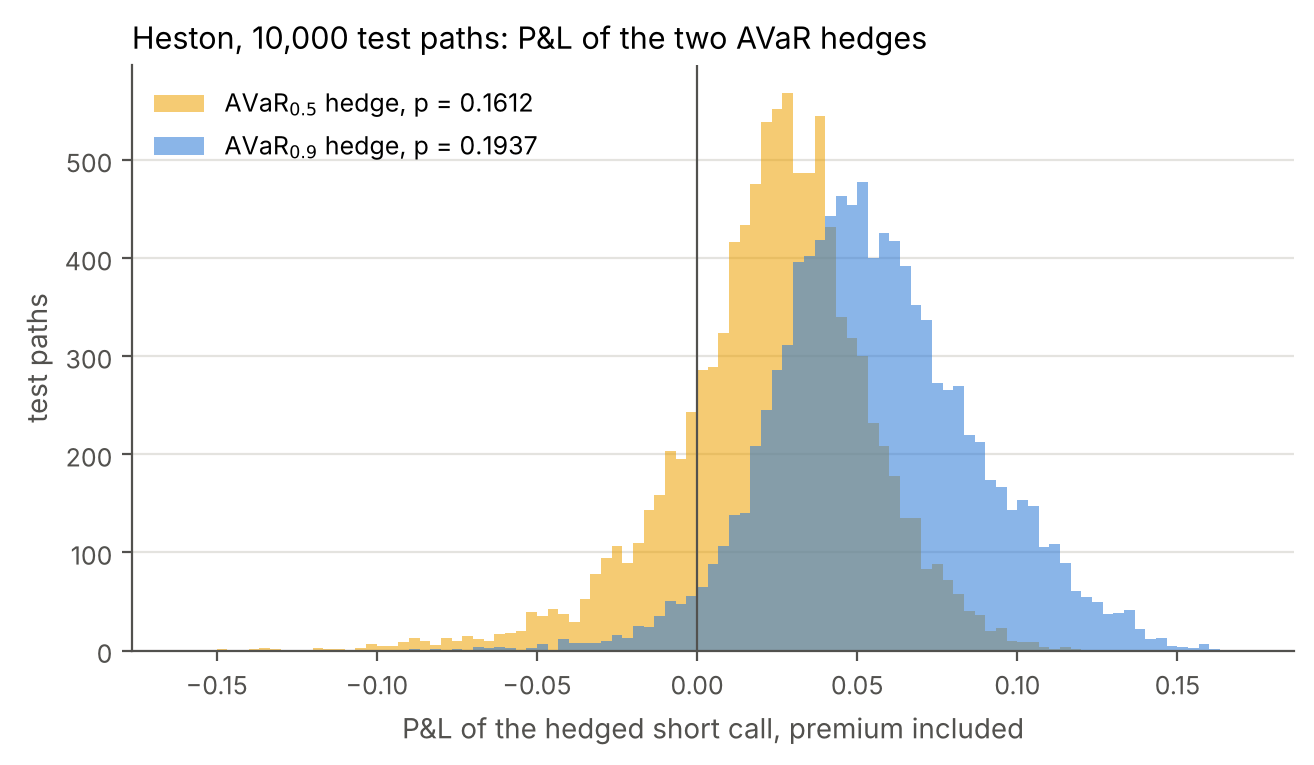

In [5]:
pnl = {alpha: price[alpha] - X_test[alpha] for alpha in alphas}
print(f"{'':12s}{'mean':>10s}{'std':>10s}{'P(loss)':>10s}{'mean of worst 10%':>20s}")
for alpha in alphas:
    x = pnl[alpha]
    print(f"{f'alpha = {alpha}':12s}{x.mean():10.5f}{x.std():10.5f}{(x < 0).float().mean():10.1%}"
          f"{x.sort().values[:len(x) // 10].mean():20.5f}")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
bins = np.linspace(-0.16, 0.17, 100)
for alpha, color in [(0.5, COLORS["other"]), (0.9, COLORS["deep"])]:
    ax.hist(pnl[alpha].numpy(), bins=bins, color=color, alpha=0.55, label=f"AVaR$_{{{alpha}}}$ hedge, p = {price[alpha]:.4f}")
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_xlabel("P&L of the hedged short call, premium included")
ax.set_ylabel("test paths")
ax.set_title("Heston, 10,000 test paths: P&L of the two AVaR hedges", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="upper left")
style(ax)
save(fig, "part2_pnl")
plt.show()

The standard deviations are almost equal (0.031 and 0.032); the difference is in the left tail, where the probability of a loss falls from 19% to 3.5%. Part of this is the higher premium, which shifts the whole histogram, and part is the strategy: at equal premium the $\alpha = 0.9$ hedge has the lower $\mathrm{AVaR}_{0.9}$ (0.1936 against 0.2013 in the table above). Each premium brings the average P&L over the seller's own worst $(1-\alpha)$ share of scenarios to zero.

## Comparison with classical hedges

Is the deep hedge any better than what a practitioner would do without it? Two Black–Scholes delta hedges: one with the constant long-run volatility $\sqrt{b}$, one with the current volatility $\sqrt{V_{t_j}}$ at each date. All strategies are evaluated on our test set and on 50 independent test sets of 10,000 paths.

In [6]:
def all_losses(S, V):
    S64, V64 = S.double(), V.double()
    with torch.no_grad():
        losses = {"no hedge": torch.relu(S64[:, -1] - K),
                  "delta, vol sqrt(b)": hedging_loss(delta_holdings(S64, b**0.5), S64)[0],
                  "delta, vol sqrt(V_t)": hedging_loss(delta_holdings(S64, V64[:, :-1].sqrt()), S64)[0]}
        for alpha, model in models.items():
            losses[f"deep, alpha = {alpha}"] = loss_of(model, S, V).double()
    return losses


ours = {name: [avar(x, lvl) for lvl in alphas] for name, x in all_losses(S_test, V_test).items()}
sets = {name: [] for name in ours}
for i in range(50):
    V_new = simulate.heston_variance(10_000, seed=2000 + i)
    S_new = simulate.heston_stock(V_new, seed=3000 + i)
    for name, x in all_losses(torch.tensor(S_new, dtype=torch.float32), torch.tensor(V_new, dtype=torch.float32)).items():
        sets[name].append([avar(x, lvl) for lvl in alphas])
sets = {name: np.array(v) for name, v in sets.items()}

print(f"{'':22s}{'AVaR_0.5':>10s}{'(50 sets)':>11s}{'AVaR_0.9':>10s}{'(50 sets)':>11s}")
for name in ours:
    print(f"{name:22s}{ours[name][0]:10.5f}{sets[name][:, 0].mean():11.5f}{ours[name][1]:10.5f}{sets[name][:, 1].mean():11.5f}")

print()
for i, alpha in enumerate(alphas):
    deep = sets[f"deep, alpha = {alpha}"][:, i]
    best = min(["delta, vol sqrt(b)", "delta, vol sqrt(V_t)"], key=lambda n: sets[n][:, i].mean())
    diff = deep - sets[best][:, i]
    print(f"AVaR_{alpha}: deep hedge vs best delta hedge ({best}): {diff.mean() / sets[best][:, i].mean():+.1%}, "
          f"deep lower in {np.sum(diff < 0)} of 50 sets")

                        AVaR_0.5  (50 sets)  AVaR_0.9  (50 sets)
no hedge                 0.27286    0.27493   0.71928    0.72217
delta, vol sqrt(b)       0.16104    0.16028   0.19807    0.19660
delta, vol sqrt(V_t)     0.16167    0.16092   0.19539    0.19393
deep, alpha = 0.5        0.16121    0.16042   0.20125    0.20000
deep, alpha = 0.9        0.16324    0.16280   0.19363    0.19254

AVaR_0.5: deep hedge vs best delta hedge (delta, vol sqrt(b)): +0.1%, deep lower in 12 of 50 sets
AVaR_0.9: deep hedge vs best delta hedge (delta, vol sqrt(V_t)): -0.7%, deep lower in 50 of 50 sets


For the cautious seller the deep hedge is the best strategy: its $\mathrm{AVaR}_{0.9}$ is 0.7% below that of the best delta hedge, and lower on all 50 test sets. For $\alpha = 0.5$ it ties with the constant-volatility delta (+0.1%). A delta hedge ignores the risk criterion, which costs little for a measure close to the median but not in the tail, which the network trained for $\alpha = 0.9$ targets directly. The gain stays modest because the stock is the only hedging instrument; with costs (part 3) it becomes much larger.

## Robustness

The prices above come from one training run and one test set. Same models on the 50 test sets, then four more training seeds:

In [7]:
for alpha in alphas:
    p_sets = []
    for i in range(50):
        V_new = simulate.heston_variance(10_000, seed=2000 + i)
        S_new = torch.tensor(simulate.heston_stock(V_new, seed=3000 + i), dtype=torch.float32)
        with torch.no_grad():
            p_sets.append(avar_objective(loss_of(models[alpha], S_new, torch.tensor(V_new, dtype=torch.float32)),
                                         models[alpha].w, alpha).item())
    print(f"alpha = {alpha}: p on 50 test sets between {min(p_sets):.5f} and {max(p_sets):.5f}, std {np.std(p_sets):.5f}")

print(f"\n{'seed':>5s}{'p_0.5':>10s}{'p_0.9':>10s}{'gap':>10s}")
print(f"{0:5d}{price[0.5]:10.5f}{price[0.9]:10.5f}{price[0.9] - price[0.5]:10.5f}")
for seed in [1, 2, 3, 4]:
    p_seed = {}
    for alpha in alphas:
        m = train(alpha, seed)
        with torch.no_grad():
            p_seed[alpha] = avar_objective(loss_of(m, S_test, V_test), m.w, alpha).item()
    print(f"{seed:5d}{p_seed[0.5]:10.5f}{p_seed[0.9]:10.5f}{p_seed[0.9] - p_seed[0.5]:10.5f}")

alpha = 0.5: p on 50 test sets between 0.15957 and 0.16128, std 0.00041


alpha = 0.9: p on 50 test sets between 0.19108 and 0.19440, std 0.00088

 seed     p_0.5     p_0.9       gap
    0   0.16122   0.19366   0.03244


    1   0.16110   0.19334   0.03225


    2   0.16128   0.19389   0.03261


    3   0.16125   0.19369   0.03244


    4   0.16122   0.19360   0.03238


Across test sets the prices move by about 0.001 (standard deviations 0.0004 and 0.0009), across seeds by less than 0.0003. Only the third decimal of the prices is uncertain, and the gap $p_{0.9} - p_{0.5} \approx 0.032$ holds for every seed.

## Limits

The simplified Broadie–Kaya step is not an exact martingale. Its one-step drift $\log \mathbb{E}[S_{t_{j+1}}/S_{t_j} \mid V_{t_j} = v]$ follows from the moment generating function of the noncentral chi-square:

In [8]:
h = T / N
c = sigma_v**2 / (4 * a) * (1 - np.exp(-a * h))
dof, u = 4 * a * b / sigma_v**2, rho / sigma_v
print(f"{'V_t':>5s}{'drift per step':>16s}{'over 30 steps':>15s}")
for v in [0.1, 0.5, 1.0]:
    nc = np.exp(-a * h) * v / c
    log_mgf = -dof / 2 * np.log(1 - 2 * u * c) + nc * u * c / (1 - 2 * u * c)     # log E[exp(u V_{t+h})]
    drift = -u * (v + a * b * h) + (a * u - 0.5) * v * h + 0.5 * (1 - rho**2) * v * h + log_mgf
    print(f"{v:5.1f}{drift:16.2e}{N * drift:15.5f}")

  V_t  drift per step  over 30 steps
  0.1        6.71e-05        0.00201
  0.5       -6.33e-06       -0.00019
  1.0       -9.81e-05       -0.00294


The drift is at most 0.003 over the 30 steps: small next to the risk loadings of 0.024 and 0.056, but not zero. Two other limits of this part: the networks observe the variance $V_t$, which is not directly observable in practice (part 6 hedges with an estimated volatility instead), and trading is still free. Part 3 adds transaction costs, back in the Black–Scholes market where the frictionless answer is known.